# MEGAN emission change: exact LMDI split vs the approximate (area-mean) split, PD

Step 6/8 of `docs/MEGAN_ATTRIBUTION.md` (user go 2026-11-15). The attribution maps of `megan_factor_maps.ipynb` split the emission change LCC_PD − CTRL_PD into composition and the MEGAN activity factors from **grid-cell, monthly, area-mean** γ's, which leaves a residual (weighting + co-variation). The branch runs give the **exact** split (LMDI-I on every patch and 30-min step, no residual). Here both are compared on the **same 6 years**.

| | Approximate (current maps) | Exact (LMDI) |
|---|---|---|
| Input | processed CLM h0 of CTRL_PD / LCC_PD (`<alias>_lnd_{BVOC,ET,LAND}_2001-2025.nc`) | `data/processed-data/megan-lmdi/megan_lmdi_PD_<year>.nc` (reduced branch output) |
| Years | 2001, 2002, 2005, 2006, 2010, 2011 (also all 25 years, for reference) | same 6 years |
| Terms (100·Δln, ≈ %) | Δln(f·ε) + Σ Δln γ_i (area-mean) + **residual** | composition (w·ε) + γ_L + γ_T + γ_P + γ_A + γ_C + cutoff (+ unexplained = 0) |
| Closure | exact only with the residual | exact (to round-off) |

**Units.** LMDI contributions C_f are absolute (kg m⁻² s⁻¹). Per cell they are put into the maps' units with 100·Δln E · C_f / ΔE (exact: they still add up to 100·Δln E). For a region, two versions: (i) the **CTRL-emission-weighted mean of the cell values**, the same statistic as under the current maps (like for like); (ii) the **regional LMDI**: 100·Δln E_R · ΣC_f·A / ΣΔE·A (the exact split of the regional total, A = cell area × land fraction).

**Run pairing.** The LMDI branches restart from CTRL_PD `-20261029` / LCC_PD `-20261028` and are bit-identical to them (identity check per year, all PASS), the same runs as the processed files (checked below).

**Driver swaps** (option 1b, also in the reduced files): the same change split into plant cover and physical driver groups (Shapley); summarised in §5.

Outputs: figures `results/figures/megan_factors/lmdi-vs-approx/`, tables `results/tables/megan_factors/`.

## 1. Setup

In [1]:
import sys
from pathlib import Path
REPO = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION")
sys.path.insert(0, str(REPO / "src"))
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy import stats
from IPython.display import display
from boreal_forest_expansion.plotting import megan_maps as mm, forcing_maps as fm, palette as pal
from boreal_forest_expansion.plotting.style import set_default_style

set_default_style()
pd.set_option("display.width", 220, "display.max_columns", 30)
LMDI_DIR = REPO / "data/processed-data/megan-lmdi"
YEARS = [2001, 2002, 2005, 2006, 2010, 2011]
GROUPS = ["isoprene", "MTERP"]
SEASONS = ["ANN", "JJA"]
LAT_MIN = 45.0
FDR_ALPHA = 0.10
MIN_EMISSION_SHARE = 0.01          # as make_attribution_maps: cells below 1 % of the CTRL p98 are masked
CTRL, LCC = fm.BVOC_PAIRS["PD"]["ctrl"], fm.BVOC_PAIRS["PD"]["lcc"]
FIG = REPO / "results/figures/megan-lmdi-vs-approx"   # layout 2026-11-16
TAB = REPO / "results/tables/megan-lmdi-vs-approx"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
FACTORS = ["composition", "gammaL", "gammaT", "gammaP", "gammaA", "gammaC", "other"]   # other = cutoff + unexplained
APPROX_OF = {"composition": "EPS", "gammaL": "GAMMAL", "gammaT": "GAMMAT", "gammaP": "GAMMAP",
             "gammaA": "GAMMAA", "gammaC": "GAMMAC", "other": "residual"}
LABEL = {"dlnE": "Δln E", "composition": "composition (f·ε / w·ε)", "gammaL": "γ_L (LAI)", "gammaT": "γ_T (temperature)",
         "gammaP": "γ_P (light)", "gammaA": "γ_A (leaf age)", "gammaC": "γ_C (CO₂)",
         "other": "residual (approx) / cutoff (LMDI)"}
print(CTRL, LCC)

CTRL_PD LCC_PD


## 2. Load both splits and check the inputs
- LMDI files: one per year; compounds and factors from the file attributes; the cases must be the branches of the processed runs.
- Internal closure of each file: Σ contributions = E_lcc − E_ctrl.
- Season means of the LMDI fields are step-weighted over the months (`nsteps`), the same weighting as CLM's monthly h0 means by record length.
- **Same emissions:** the LMDI grid-cell emission (vegetated patches ≥ 45°N) must equal the h0 `MEG_*` of the processed runs (both in kg m⁻² s⁻¹ per grid-cell land area). This also checks that the two splits describe the same runs.
- **2000 chain (2001, 2002):** the hybrid-start branches write daily files 00:00–23:30, so their reduced months are shifted by one 30-min step against the h0 months; the check allows that (≤ 1 %), the 2005/2010 chains must match to round-off.


In [2]:
lm = {}
for y in YEARS:
    ds = xr.open_dataset(LMDI_DIR / f"megan_lmdi_PD_{y}.nc")
    comps, facs = ds.attrs["compounds"].split(","), ds.attrs["factors"].split(",")
    month = ds["month"].values % 100
    ds = ds.assign_coords(compound=comps, factor=facs, month=month)
    assert ds.attrs["ctrl_case"].startswith("NF2000norbc_tropstratchem_nudg_ctrl_meganpatch"), ds.attrs["ctrl_case"]
    assert ds.attrs["lcc_case"].startswith("NF2000norbc_tropstratchem_nudg_lcc_meganpatch"), ds.attrs["lcc_case"]
    assert list(month) == list(range(1, 13)), f"{y}: months {month}"
    err = float(abs(ds["contribution"].sum("factor") - (ds["E_lcc"] - ds["E_ctrl"])).max() / abs(ds["E_lcc"]).max())
    print(f"{y}: {ds.attrs['ctrl_case']} / {ds.attrs['lcc_case']}; closure {err:.1e}; checks: "
          f"{'all pass' if 'fail' not in ds.attrs['checks'].lower() else 'FAIL'}")
    assert err < 1e-10
    lm[y] = ds
assert set(mm.GROUPS["MTERP"]) <= set(comps) and "isoprene" in comps

def lmdi_season(ds, group, season):
    """Step-weighted season mean of E_ctrl, E_lcc, contributions (summed over the group's compounds)."""
    months = mm.SEASONS[season]
    w = ds["nsteps"].where(ds["month"].isin(months), 0).astype(float)
    w = w / w.sum()
    c = ds.sel(compound=mm.GROUPS[group])
    E0 = (c["E_ctrl"].sum("compound") * w).sum("month")
    E1 = (c["E_lcc"].sum("compound") * w).sum("month")
    C = (c["contribution"].sum("compound") * w).sum("month")
    C = xr.concat([C.sel(factor=f, drop=True) for f in FACTORS[:-1]] + [C.sel(factor=["cutoff", "unexplained"]).sum("factor")],
                  dim=pd.Index(FACTORS, name="factor"))
    return E0, E1, C

def to_dln(E0, E1, C):
    """100·Δln E · C / ΔE per cell (the maps' units); the limit 100·C/E where ΔE = 0."""
    dE = E1 - E0
    ok = (E0 > 0) & (E1 > 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        scale = xr.where(abs(dE) > 1e-12 * E0, 100 * np.log(E1 / E0) / dE, 100 / E0)
    return (C * scale).where(ok), (100 * np.log(E1 / E0)).where(ok)

2001: NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2000 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2000; closure 1.1e-15; checks: all pass
2002: NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2000 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2000; closure 7.9e-16; checks: all pass
2005: NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2005 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2005; closure 1.3e-15; checks: all pass
2006: NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2005 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2005; closure 6.4e-16; checks: all pass
2010: NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2010 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261106-from2010; closure 9.1e-16; checks: all pass
2011: NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19

In [3]:
# approximate split (same code path as make_attribution_maps), all 25 years, then the 6 years
def approx_split(group, season):
    a = mm.load_factors(CTRL, group, season, 2001, 2025)
    b = mm.load_factors(LCC, group, season, 2001, 2025)
    def dln(x, y):
        return 100 * np.log(y / x).where((x > 0) & (y > 0))
    partial = [f for f in ["GAMMAL", "GAMMAT", "GAMMAP", "GAMMAA", "GAMMAC"] if f in a]
    d = {"dlnE": dln(a["MEG"], b["MEG"]), "EPS": dln(a["EPS"] * a["f_valid"], b["EPS"] * b["f_valid"]),
         "gamma_eff": dln(a["gamma_eff"], b["gamma_eff"])}
    for f in partial:
        d[f] = dln(a[f], b[f])
    d["GAMMAC"] = d.get("GAMMAC", xr.zeros_like(d["dlnE"]))
    d["residual"] = d["gamma_eff"] - sum(d[f] for f in partial)
    return a, b, d

data, consistency = {}, []
bv = fm.open_class(CTRL, "BVOC", 2001, 2025, "lnd")
area_land = (bv["area"] * bv["landfrac"]).fillna(0)             # km2 of land per cell
for group in GROUPS:
    for season in SEASONS:
        a, b, d = approx_split(group, season)
        per_year = {}
        for y in YEARS:
            E0, E1, C = lmdi_season(lm[y], group, season)
            Cln, dlnE = to_dln(E0, E1, C)
            per_year[y] = dict(E0=E0, E1=E1, C=C, Cln=Cln, dlnE=dlnE)
            # same emissions: LMDI grid-cell E vs h0 MEG (mg m-2 d-1 -> kg m-2 s-1), cells >= 45N with emission
            for name, E, meg in (("CTRL", E0, a["MEG"]), ("LCC", E1, b["MEG"])):
                m = meg.sel(year=y) / (1e6 * 86400)
                sel = (m["lat"] >= LAT_MIN) & (m > 0)
                r = float((abs(E - m) / m.where(sel)).max())
                consistency.append(dict(group=group, season=season, year=y, run=name, max_rel_diff=r))
        data[group, season] = dict(a=a, b=b, d=d, lmdi=per_year)
cons = pd.DataFrame(consistency)
cons["chain"] = np.where(cons["year"] < 2005, "2000 (hybrid)", "2005/2010 (restart)")
display(cons.groupby(["chain", "group", "season", "run"])["max_rel_diff"].max().to_frame())
# 2005/2010 chains: identical to round-off. 2000 chain (2001, 2002): its daily tape-2 files run 00:00–23:30 instead of
# 00:30–24:00 (hybrid start), so each reduced month holds the 00:00 step of its first day and misses that of the next
# month: a 30-min shift of the month boundaries (found 2026-11-15; <= 0.3 % on monthly means at a few cells).
# 2001/2002 re-reduced 2026-11-16 with each step in the month of its own stamp: all years must match to round-off
assert cons["max_rel_diff"].max() < 1e-10, "LMDI emissions differ from the processed MEG_*"

max_rel_diff
chain               group    season run               
2000 (hybrid)       MTERP    ANN    CTRL  1.369310e-15
                                    LCC   1.352600e-15
                             JJA    CTRL  1.498968e-15
                                    LCC   1.362806e-15
                    isoprene ANN    CTRL  3.087265e-15
                                    LCC   3.288271e-15
                             JJA    CTRL  3.466146e-15
                                    LCC   3.534388e-15
2005/2010 (restart) MTERP    ANN    CTRL  1.439649e-15
                                    LCC   1.369874e-15
                             JJA    CTRL  2.205347e-15
                                    LCC   1.581117e-15
                    isoprene ANN    CTRL  3.096856e-15
                                    LCC   3.104089e-15
                             JJA    CTRL  3.375688e-15
                                    LCC   3.019300e-15

## 3. Regional means: approximate vs exact, ≥ 45°N and modified cells
Per year: CTRL-emission-weighted mean of the cell values (approx and LMDI, like for like) and the regional LMDI; then mean ± 95 % t-interval over the 6 years. The approximate split on all 25 years (2001–2025) shows whether the 6 years are representative.

In [4]:
def t_ci(x):
    x = np.asarray(x, float)
    return x.mean(), stats.t.ppf(0.975, x.size - 1) * x.std(ddof=1) / np.sqrt(x.size)

rows = []
for (group, season), D in data.items():
    a, d, L = D["a"], D["d"], D["lmdi"]
    e_ctrl = a["MEG"].mean("year")
    thr = MIN_EMISSION_SHARE * float(np.nanquantile(e_ctrl.where(e_ctrl["lat"] >= LAT_MIN).values, 0.98))
    keep = e_ctrl > thr
    w_em = (e_ctrl * np.cos(np.deg2rad(e_ctrl["lat"]))).where(keep, 0)
    mod = mm._modified_mask(e_ctrl)
    regions = {"≥45°N": e_ctrl["lat"] >= LAT_MIN, "modified cells": (mod > 0) if mod is not None else None}
    for region, rmask in regions.items():
        if rmask is None:
            continue
        def cellmean(x):
            m = rmask & np.isfinite(x) & (w_em > 0)
            return float((x * w_em).where(m).sum() / w_em.where(m).sum())
        for key in ["dlnE"] + FACTORS:
            ak = "dlnE" if key == "dlnE" else APPROX_OF[key]
            ap6 = [cellmean(d[ak].sel(year=y)) for y in YEARS]
            ap25 = [cellmean(d[ak].sel(year=y)) for y in d[ak]["year"].values]
            lm_c = [cellmean(L[y]["dlnE"] if key == "dlnE" else L[y]["Cln"].sel(factor=key)) for y in YEARS]
            lm_r = []
            for y in YEARS:
                A = area_land.where(rmask, 0)
                E0R, E1R = float((L[y]["E0"] * A).sum()), float((L[y]["E1"] * A).sum())
                dlnR = 100 * np.log(E1R / E0R)
                lm_r.append(dlnR if key == "dlnE" else dlnR * float((L[y]["C"].sel(factor=key) * A).sum()) / (E1R - E0R))
            for method, vals in (("approx, 25 yr", ap25), ("approx, 6 yr", ap6), ("LMDI, cell mean", lm_c),
                                 ("LMDI, regional", lm_r)):
                m, h = t_ci(vals)
                rows.append(dict(group=group, season=season, region=region, term=key, method=method,
                                 mean=m, ci95=h, n=len(vals)))
reg = pd.DataFrame(rows)
reg.to_csv(TAB / "megan_lmdi_vs_approx_regional_PD.csv", index=False)
fmt = reg.assign(v=lambda t: t["mean"].map("{:+.1f}".format) + " ± " + t["ci95"].map("{:.1f}".format))
for region in ("≥45°N", "modified cells"):
    print(f"\n{region}: 100·Δln (≈ %), mean ± 95 % CI over years")
    display(fmt[fmt.region == region].pivot_table(index=["group", "season", "term"], columns="method", values="v",
                                                  aggfunc="first")
            .reindex(columns=["approx, 25 yr", "approx, 6 yr", "LMDI, cell mean", "LMDI, regional"])
            .reindex(["dlnE"] + FACTORS, level=2))


≥45°N: 100·Δln (≈ %), mean ± 95 % CI over years


method                      approx, 25 yr approx, 6 yr LMDI, cell mean LMDI, regional
group    season term                                                                 
MTERP    ANN    dlnE           -0.8 ± 0.2   -0.6 ± 0.8      -0.6 ± 0.8     +0.9 ± 0.9
                composition    +2.0 ± 0.0   +2.0 ± 0.0      -4.7 ± 0.0     -3.3 ± 0.2
                gammaL         -4.0 ± 0.2   -3.6 ± 0.4      +3.8 ± 0.7     +3.8 ± 0.7
                gammaT         +2.2 ± 0.1   +2.0 ± 0.3      +0.5 ± 0.2     +0.6 ± 0.2
                gammaP         -0.1 ± 0.0   -0.1 ± 0.0      +0.0 ± 0.0     +0.0 ± 0.0
                gammaA         +0.1 ± 0.0   +0.1 ± 0.0      -0.2 ± 0.0     -0.2 ± 0.1
                gammaC         +0.0 ± 0.0   +0.0 ± 0.0      +0.0 ± 0.0     +0.0 ± 0.0
                other          -1.0 ± 0.0   -1.0 ± 0.2      +0.0 ± 0.0     +0.0 ± 0.0
         JJA    dlnE           +0.0 ± 0.2   +0.0 ± 0.8      +0.0 ± 0.8     +1.4 ± 0.9
                composition    +2.5 ± 0.0   +2.5 ± 0.0      -4.2 ± 0.1     -2.8 ± 0.4
                gammaL         -3.4 ± 0.2   -3.1 ± 0.4      +3.9 ± 0.6     +3.9 ± 0.7
                gammaT         +2.7 ± 0.2   +2.4 ± 0.4      +0.6 ± 0.3     +0.6 ± 0.3
                gammaP         -0.2 ± 0.0   -0.2 ± 0.0      +0.0 ± 0.0     +0.0 ± 0.0
                gammaA         -0.1 ± 0.1   -0.1 ± 0.2      -0.2 ± 0.1     -0.3 ± 0.1
                gammaC         +0.0 ± 0.0   +0.0 ± 0.0      +0.0 ± 0.0     +0.0 ± 0.0
                other          -1.5 ± 0.1   -1.4 ± 0.2      +0.0 ± 0.0     +0.0 ± 0.0
isoprene ANN    dlnE           +2.1 ± 0.3   +1.9 ± 1.0      +1.9 ± 1.0     +2.8 ± 1.2
                composition   +12.4 ± 0.0  +12.4 ± 0.0      -2.2 ± 0.2     -1.3 ± 0.6
                gammaL         -3.3 ± 0.2   -3.0 ± 0.4      +3.4 ± 0.5     +3.5 ± 0.7
                gammaT         +2.6 ± 0.2   +2.4 ± 0.4      +0.5 ± 0.4     +0.5 ± 0.4
                gammaP         -0.1 ± 0.0   -0.1 ± 0.1      -0.1 ± 0.1     -0.1 ± 0.1
                gammaA         -0.0 ± 0.0   -0.0 ± 0.0      +0.3 ± 0.0     +0.3 ± 0.0
                gammaC         +0.0 ± 0.0   +0.0 ± 0.0      +0.0 ± 0.0     +0.0 ± 0.0
                other          -9.6 ± 0.1   -9.8 ± 0.4      +0.0 ± 0.0     +0.0 ± 0.0
         JJA    dlnE           +2.5 ± 0.3   +2.2 ± 1.0      +2.2 ± 1.0     +3.1 ± 1.3
                composition   +12.3 ± 0.0  +12.3 ± 0.0      -2.0 ± 0.2     -0.9 ± 0.6
                gammaL         -2.6 ± 0.2   -2.3 ± 0.6      +3.5 ± 0.6     +3.5 ± 0.8
                gammaT         +2.8 ± 0.3   +2.4 ± 0.5      +0.5 ± 0.5     +0.4 ± 0.4
                gammaP         -0.4 ± 0.1   -0.5 ± 0.2      -0.1 ± 0.1     -0.2 ± 0.1
                gammaA         +0.0 ± 0.0   +0.0 ± 0.1      +0.3 ± 0.0     +0.3 ± 0.0
                gammaC         +0.0 ± 0.0   +0.0 ± 0.0      +0.0 ± 0.0     +0.0 ± 0.0
                other          -9.5 ± 0.1   -9.6 ± 0.5      +0.0 ± 0.0     +0.0 ± 0.0


modified cells: 100·Δln (≈ %), mean ± 95 % CI over years


method                      approx, 25 yr approx, 6 yr LMDI, cell mean LMDI, regional
group    season term                                                                 
MTERP    ANN    dlnE           -1.8 ± 0.2   -1.7 ± 0.9      -1.7 ± 0.9     +0.9 ± 1.0
                composition    +3.5 ± 0.0   +3.5 ± 0.0      -8.5 ± 0.0     -5.7 ± 0.4
                gammaL         -7.2 ± 0.2   -6.8 ± 0.7      +6.4 ± 0.8     +6.2 ± 0.7
                gammaT         +3.8 ± 0.2   +3.5 ± 0.3      +0.7 ± 0.2     +0.8 ± 0.3
                gammaP         -0.2 ± 0.0   -0.2 ± 0.0      +0.0 ± 0.0     +0.0 ± 0.0
                gammaA         +0.2 ± 0.0   +0.2 ± 0.0      -0.3 ± 0.1     -0.4 ± 0.1
                gammaC         +0.0 ± 0.0   +0.0 ± 0.0      +0.0 ± 0.0     +0.0 ± 0.0
                other          -1.9 ± 0.1   -2.0 ± 0.2      +0.0 ± 0.0     +0.0 ± 0.0
         JJA    dlnE           -0.4 ± 0.2   -0.6 ± 0.9      -0.6 ± 0.9     +1.8 ± 1.0
                composition    +4.4 ± 0.0   +4.4 ± 0.0      -7.3 ± 0.1     -4.7 ± 0.6
                gammaL         -5.9 ± 0.3   -5.5 ± 0.6      +6.4 ± 0.7     +6.1 ± 0.7
                gammaT         +4.3 ± 0.2   +3.9 ± 0.5      +0.8 ± 0.3     +0.9 ± 0.4
                gammaP         -0.4 ± 0.0   -0.4 ± 0.1      -0.0 ± 0.0     -0.0 ± 0.1
                gammaA         -0.2 ± 0.1   -0.3 ± 0.3      -0.4 ± 0.1     -0.5 ± 0.1
                gammaC         +0.0 ± 0.0   +0.0 ± 0.0      +0.0 ± 0.0     +0.0 ± 0.0
                other          -2.6 ± 0.1   -2.6 ± 0.3      +0.0 ± 0.0     +0.0 ± 0.0
isoprene ANN    dlnE           +3.9 ± 0.4   +3.7 ± 1.4      +3.7 ± 1.4     +5.5 ± 1.7
                composition   +28.8 ± 0.0  +28.8 ± 0.0      -5.2 ± 0.5     -3.0 ± 1.3
                gammaL         -7.7 ± 0.3   -7.4 ± 0.7      +7.8 ± 1.1     +7.5 ± 1.0
                gammaT         +5.4 ± 0.3   +5.1 ± 0.5      +0.5 ± 0.4     +0.5 ± 0.5
                gammaP         -0.3 ± 0.1   -0.3 ± 0.2      -0.2 ± 0.1     -0.3 ± 0.1
                gammaA         -0.1 ± 0.0   -0.1 ± 0.0      +0.7 ± 0.1     +0.7 ± 0.1
                gammaC         +0.0 ± 0.0   +0.0 ± 0.0      -0.0 ± 0.0     -0.0 ± 0.0
                other         -22.3 ± 0.2  -22.4 ± 0.6      +0.1 ± 0.0     +0.1 ± 0.0
         JJA    dlnE           +4.8 ± 0.4   +4.3 ± 1.4      +4.3 ± 1.4     +6.3 ± 1.9
                composition   +28.2 ± 0.0  +28.2 ± 0.0      -4.5 ± 0.5     -2.2 ± 1.4
                gammaL         -6.0 ± 0.3   -5.8 ± 0.7      +7.9 ± 1.1     +7.6 ± 1.0
                gammaT         +5.5 ± 0.3   +4.9 ± 0.6      +0.4 ± 0.5     +0.4 ± 0.5
                gammaP         -1.2 ± 0.1   -1.4 ± 0.2      -0.3 ± 0.2     -0.4 ± 0.2
                gammaA         +0.0 ± 0.1   +0.0 ± 0.2      +0.9 ± 0.2     +0.8 ± 0.2
                gammaC         +0.0 ± 0.0   -0.0 ± 0.0      -0.0 ± 0.0     -0.0 ± 0.0
                other         -21.7 ± 0.2  -21.7 ± 0.6      +0.1 ± 0.1     +0.1 ± 0.0

In [5]:
# where does the approximate residual go?  per factor: LMDI (cell mean) − approx (6 yr); they add up to
# residual_approx − cutoff_LMDI + (dlnE difference, ≈ 0)
mv = reg[(reg.method.isin(["approx, 6 yr", "LMDI, cell mean"]))].pivot_table(
    index=["group", "season", "region", "term"], columns="method", values="mean")
mv["LMDI − approx"] = mv["LMDI, cell mean"] - mv["approx, 6 yr"]
moved = mv["LMDI − approx"].unstack("term").reindex(columns=["dlnE"] + FACTORS)
display(moved.round(1))
moved.to_csv(TAB / "megan_lmdi_minus_approx_PD.csv")

term                            dlnE  composition  gammaL  gammaT  gammaP  gammaA  gammaC  other
group    season region                                                                          
MTERP    ANN    modified cells   0.0        -12.0    13.2    -2.9     0.3    -0.5     0.0    2.0
                ≥45°N            0.0         -6.7     7.4    -1.6     0.1    -0.3     0.0    1.0
         JJA    modified cells   0.0        -11.7    11.9    -3.1     0.4    -0.2     0.0    2.6
                ≥45°N            0.0         -6.7     7.0    -1.8     0.2    -0.1     0.0    1.4
isoprene ANN    modified cells   0.0        -34.0    15.2    -4.6     0.1     0.8    -0.0   22.4
                ≥45°N           -0.0        -14.7     6.5    -1.9     0.0     0.3    -0.0    9.8
         JJA    modified cells   0.0        -32.7    13.6    -4.5     1.0     0.8    -0.0   21.8
                ≥45°N            0.0        -14.3     5.8    -1.9     0.4     0.3     0.0    9.7

## 4. Maps: approximate | exact | exact − approximate (6-year means)
Rows = Δln E and the factors; last row = residual (approx) and cutoff (LMDI). Same colour scale as the current attribution maps (PD ±60) for the first two columns; own scale for the difference. Hatched: not FDR-significant (paired t-test over the 6 years, α = 0.10); solid line = limit of the perturbed vegetation cells, dashed line = broadleaf/needleleaf expansion border (display only); second and third number under each map = same mean over the broadleaf- and needleleaf-expansion cells (broadleaf replaces needleleaf / other tree gain, mostly needleleaf) (cells with ≤ 1 pp tree gain left out, draft Supplementary Sect. S1). Cells with CTRL emission < 1 % of its 98th percentile are masked, as in the current maps.

findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan-lmdi-vs-approx/PD_isoprene_lmdi_vs_approx_ANN.png


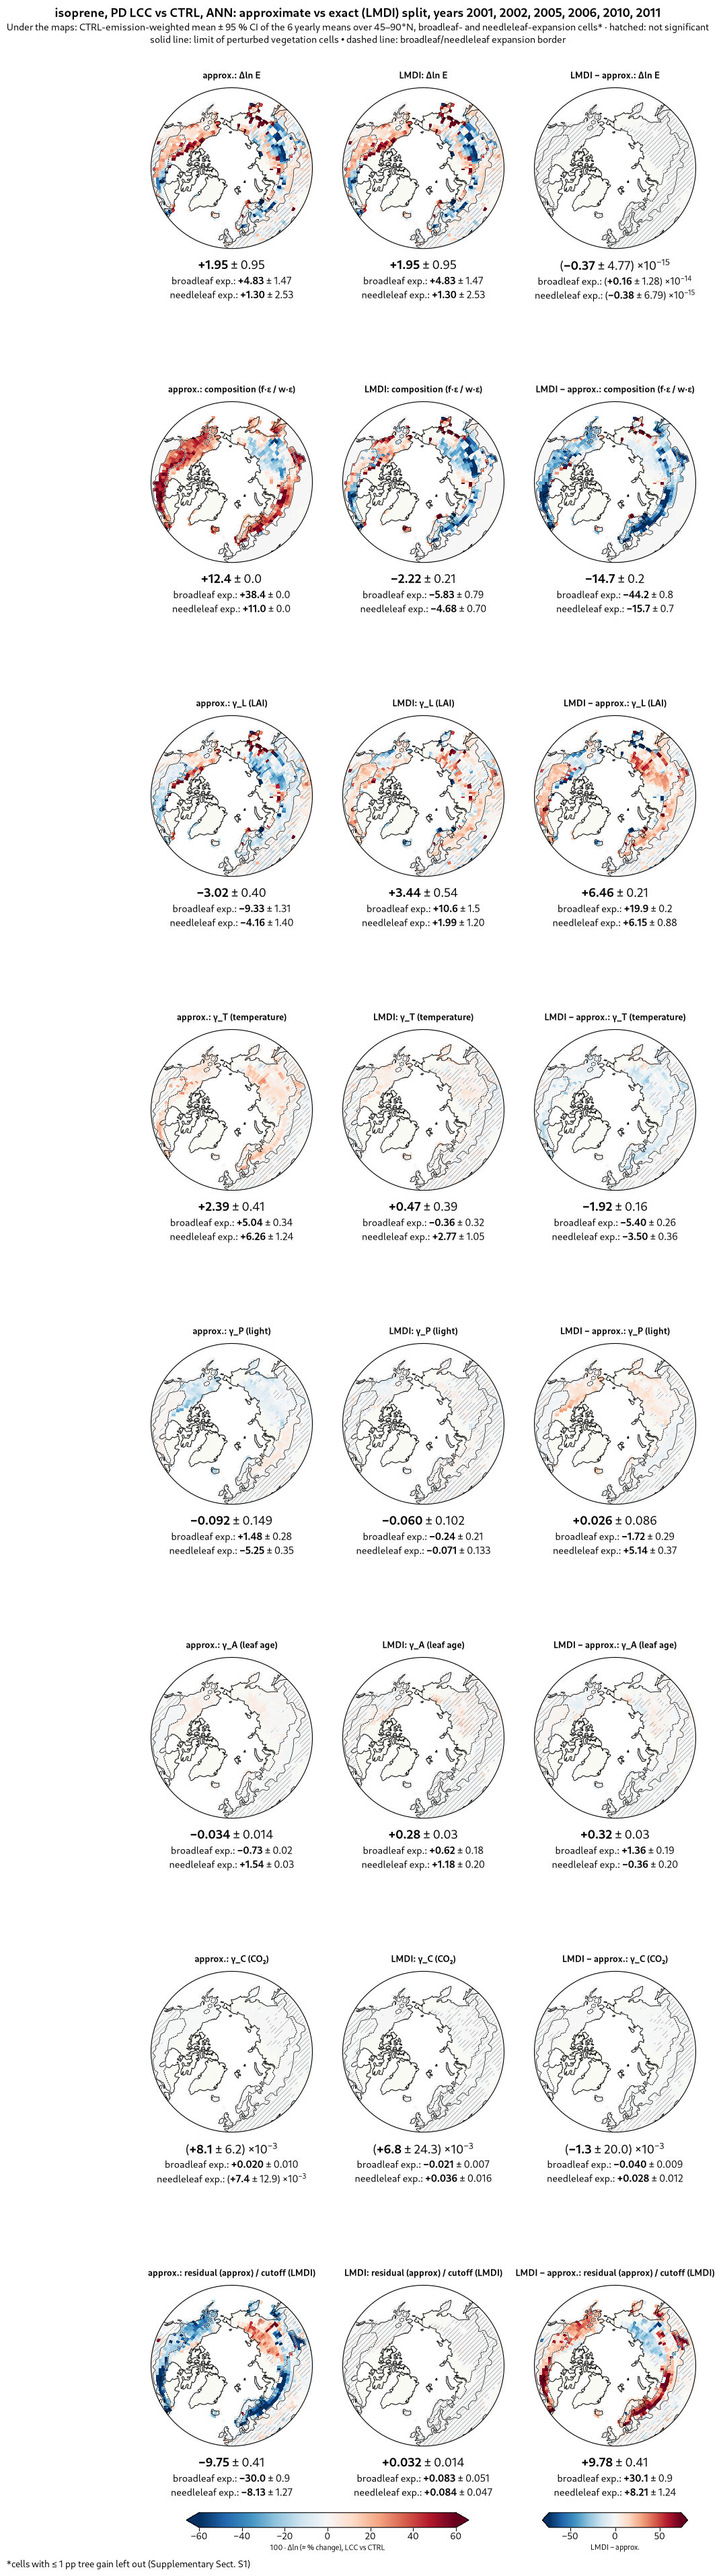

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan-lmdi-vs-approx/PD_isoprene_lmdi_vs_approx_JJA.png


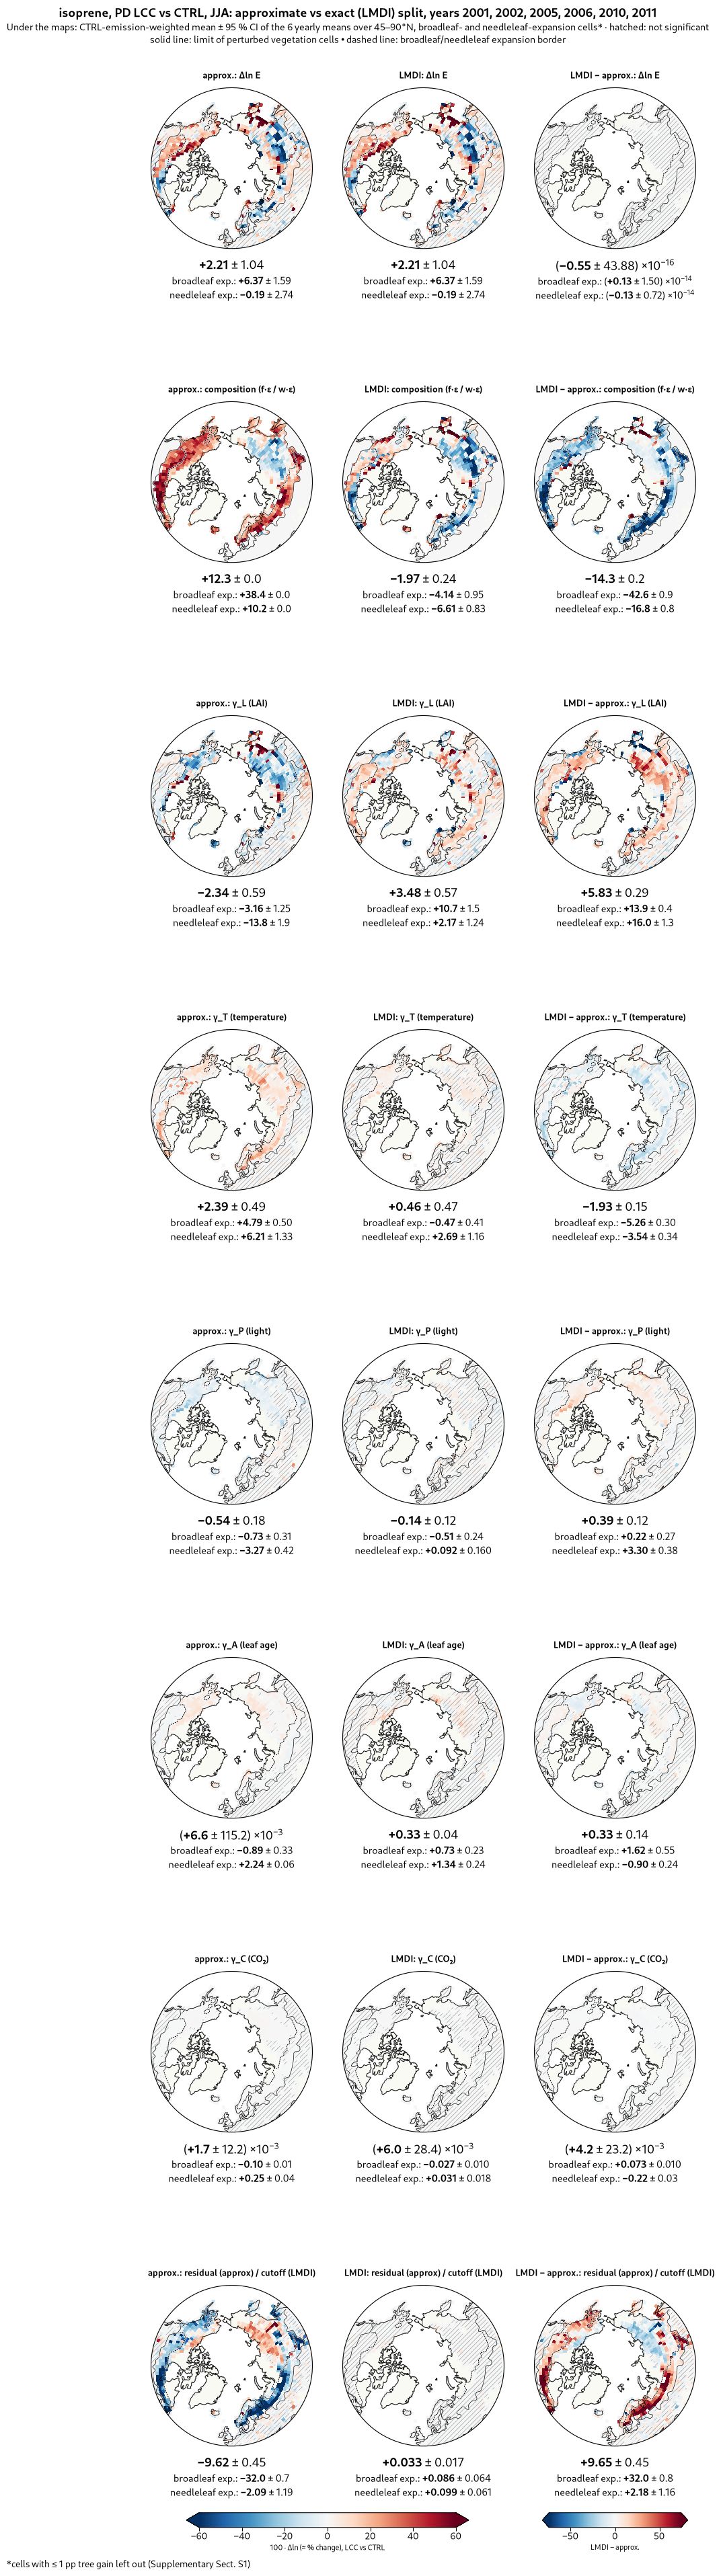

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan-lmdi-vs-approx/PD_MTERP_lmdi_vs_approx_ANN.png


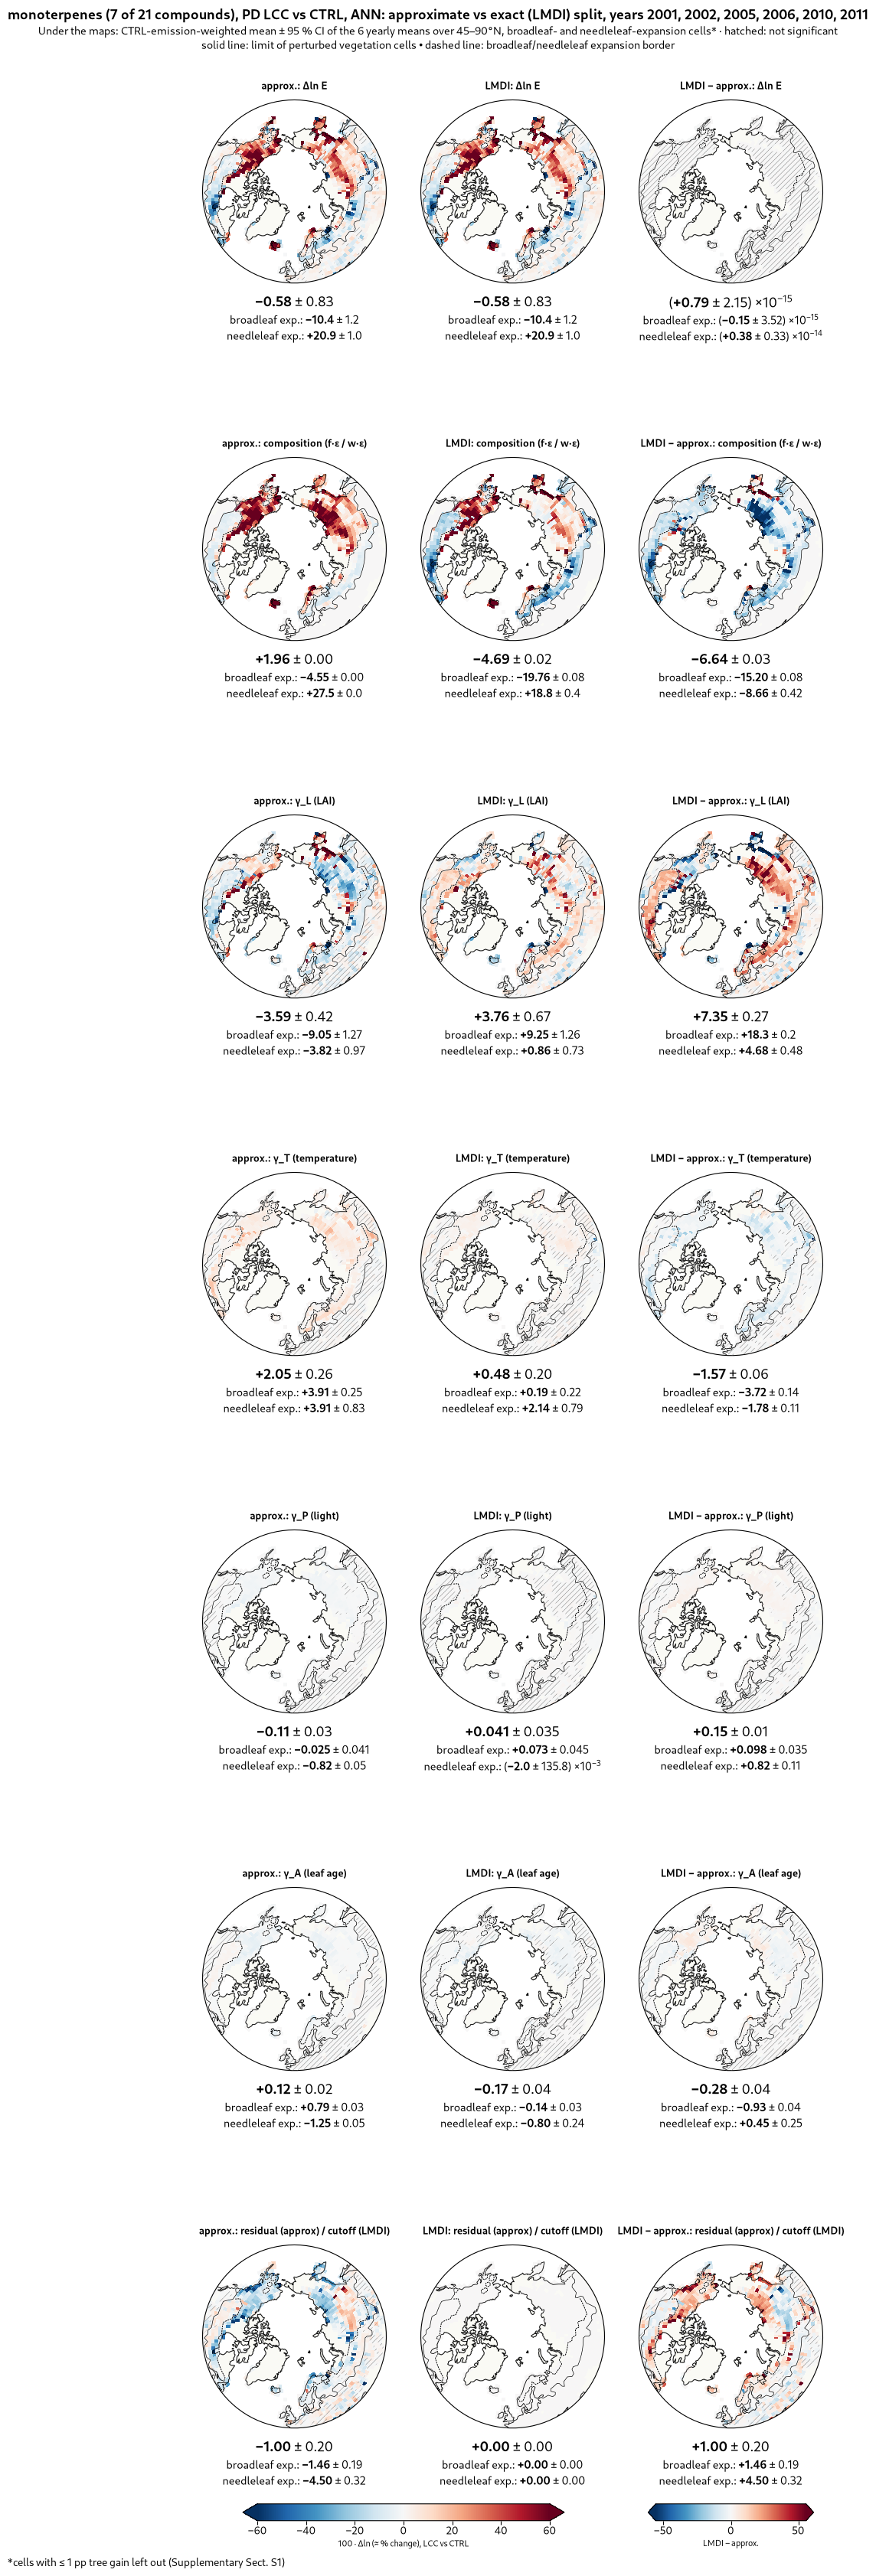

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan-lmdi-vs-approx/PD_MTERP_lmdi_vs_approx_JJA.png


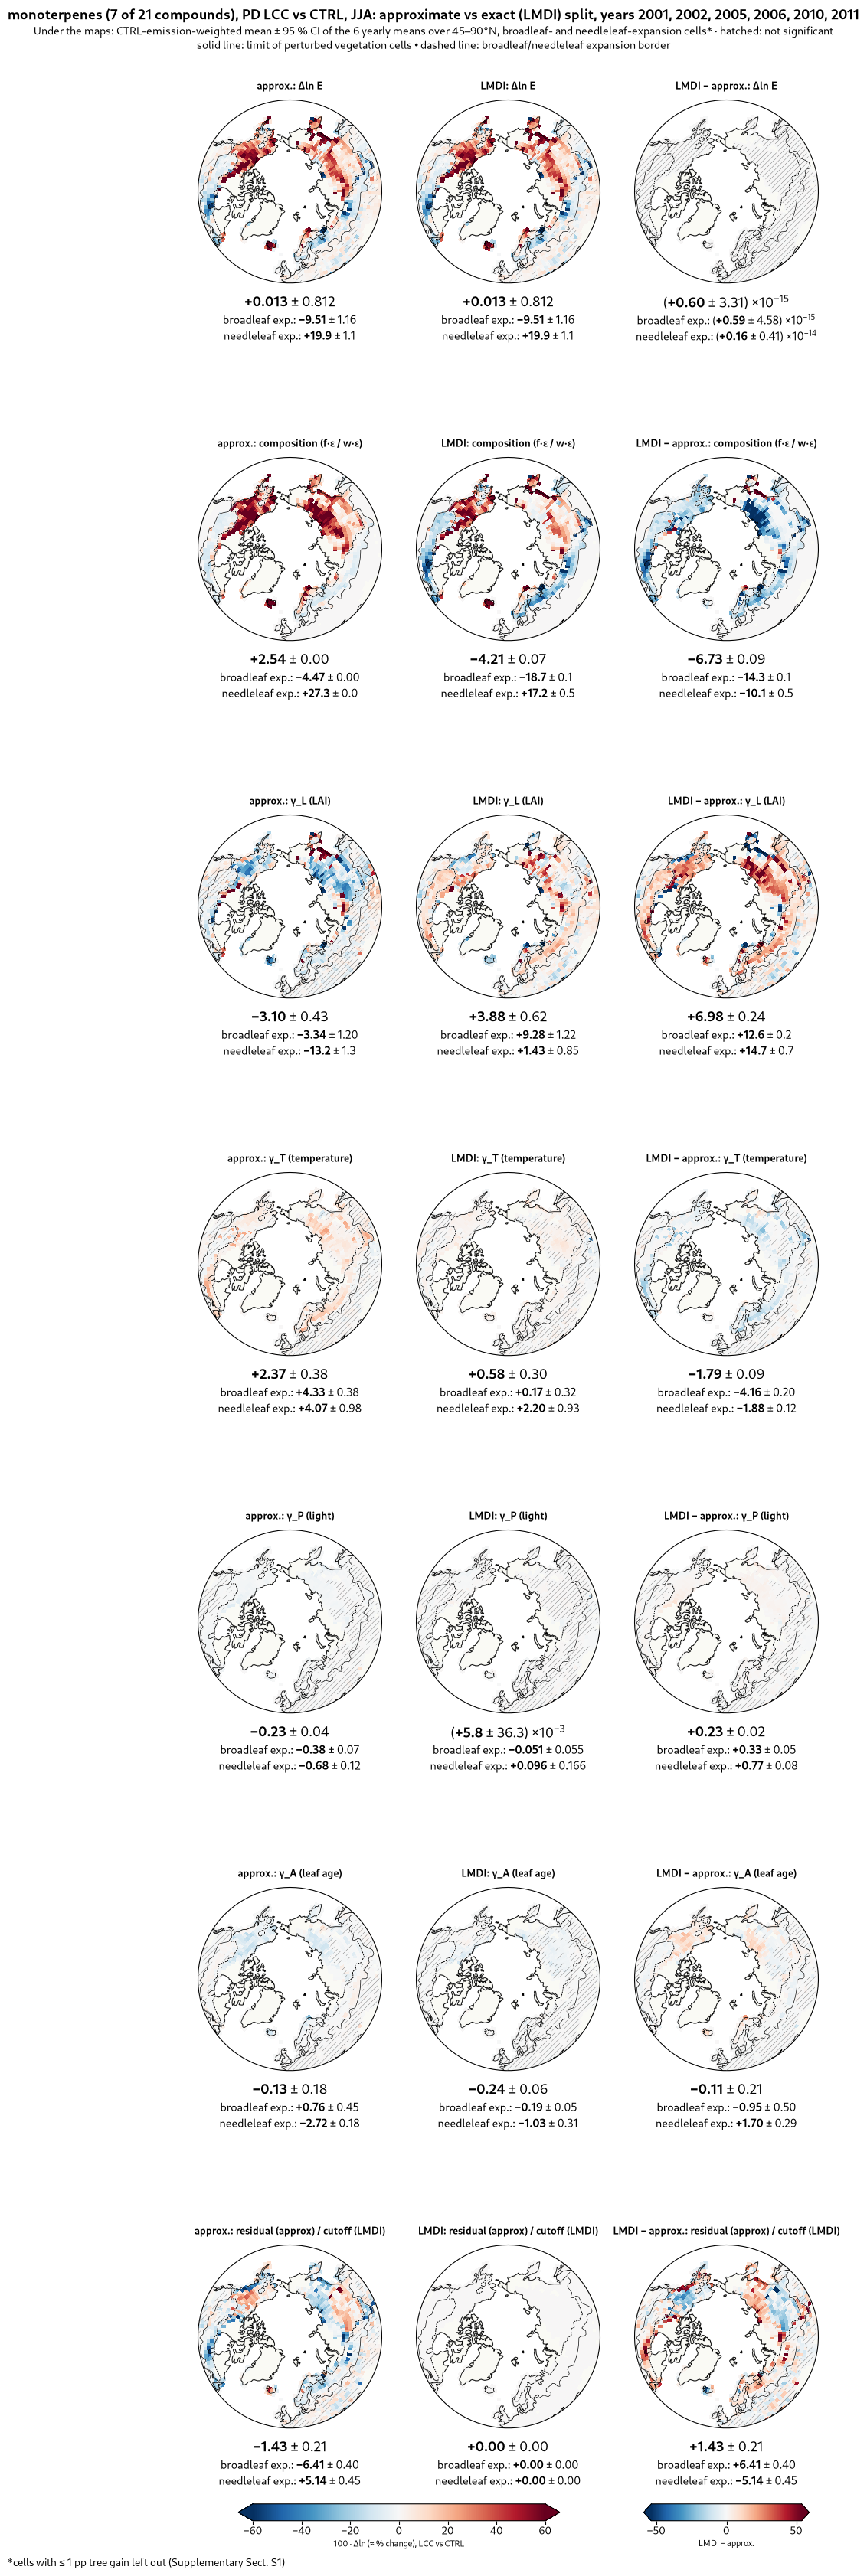

In [6]:
v, step = mm.ATTRIBUTION_VMAX["PD"]
for (group, season), D in data.items():
    a, d, L = D["a"], D["d"], D["lmdi"]
    e_ctrl = a["MEG"].mean("year")
    thr = MIN_EMISSION_SHARE * float(np.nanquantile(e_ctrl.where(e_ctrl["lat"] >= LAT_MIN).values, 0.98))
    keep = e_ctrl > thr
    w_em = (e_ctrl * np.cos(np.deg2rad(e_ctrl["lat"]))).where(keep, 0)
    mod = mm._modified_mask(e_ctrl)
    keys = ["dlnE"] + [k for k in FACTORS if not (k == "gammaC" and group != "isoprene")]
    ap = {k: d["dlnE" if k == "dlnE" else APPROX_OF[k]].sel(year=YEARS).where(keep) for k in keys}
    ex = {k: xr.concat([L[y]["dlnE"] if k == "dlnE" else L[y]["Cln"].sel(factor=k, drop=True) for y in YEARS],
                       dim=pd.Index(YEARS, name="year")).where(keep) for k in keys}
    diff = {k: ex[k] - ap[k] for k in keys}
    vd = fm.symmetric_vmax(xr.concat([diff[k].mean("year") for k in keys[1:]], "k").where(e_ctrl["lat"] >= LAT_MIN),
                           q=0.98, fallback=10.0)
    norms = [mcolors.TwoSlopeNorm(vmin=-v, vcenter=0, vmax=v)] * 2 + [mcolors.TwoSlopeNorm(vmin=-vd, vcenter=0, vmax=vd)]
    fig, axes = fm.map_grid(len(keys), 3, left=2.2, titles_every_row=True)
    mappable = {}
    for i, k in enumerate(keys):
        for j, (src, name) in enumerate(((ap, "approx."), (ex, "LMDI"), (diff, "LMDI − approx."))):
            x = src[k]
            mean, half = mm._interval(x, w_em, LAT_MIN)
            p = mm._panel(axes[i, j], x.mean("year"), norms[j], "RdBu_r", f"{name}: {LABEL[k]}", LAT_MIN,
                          not_sig=mm._not_significant(x, LAT_MIN, FDR_ALPHA), modified=mod,
                          text=fm._format_interval(mean, half),
                          region_text=mm._region_texts(x, lambda r, y=x: mm._interval(y.where(r), w_em, LAT_MIN)))
            mappable[j] = p
    fm._cbar_below(fig, axes[-1, 0:2], mappable[0], "100 · Δln (≈ % change), LCC vs CTRL", fm.CBAR_LABELSIZE_SHARED, shrink=0.8)
    fm._cbar_below(fig, axes[-1, 2:3], mappable[2], "LMDI − approx.", fm.CBAR_LABELSIZE_SHARED, shrink=0.9)
    mm._title(fig, f"{mm.GROUP_TITLE[group]}, PD LCC vs CTRL, {season}: approximate vs exact (LMDI) split, "
                   f"years {', '.join(map(str, YEARS))}",
              f"Under the maps: CTRL-emission-weighted mean ± 95 % CI of the 6 yearly means {mm._regions_subtitle(LAT_MIN)}"
              f" · hatched: not significant{mm._outline_note()}")
    path = FIG / f"PD_{group}_lmdi_vs_approx_{season}.png"
    fm.add_region_footnote(fig)
    fig.savefig(path, dpi=200, bbox_inches="tight"); print("Saved", path)
    plt.show(); plt.close(fig)

## 5. Physical drivers (driver swaps, option 1b): regional split ≥ 45°N
Exact, order-free split of the regional emission change into plant cover and driver groups (Shapley values over the 4 groups), from the per-pair monthly integrals `swap4`. Share of the regional ΔE (%), mean ± 95 % CI over the 6 years. A = cell land area of the pair.

In [7]:
srows = []
for y in YEARS:
    ds = lm[y]
    terms = ds.attrs["terms4"].split(",")
    A = ds["pair_area"] if "pair_area" in ds else None
    for group in GROUPS:
        for season in SEASONS:
            months = mm.SEASONS[season]
            c = ds.sel(compound=mm.GROUPS[group])
            sel = c["month"].isin(months)
            dEp = ((c["Ep_lcc"] - c["Ep_ctrl"]).sum("compound").where(sel, 0).sum("month") * A).sum("pair")
            S = (c["swap4"].sum("compound").where(sel, 0).sum("month") * A).sum("pair")
            for it, t in enumerate(terms):
                srows.append(dict(group=group, season=season, year=y, term=t, share=100 * float(S.isel(term4=it) / dEp)))
sw = pd.DataFrame(srows)
chk = sw.groupby(["group", "season", "year"])["share"].sum()
print("sum of shares (must be 100):", chk.min().round(6), chk.max().round(6))
swt = sw.groupby(["group", "season", "term"])["share"].apply(lambda x: "{:+.1f} ± {:.1f}".format(*t_ci(x))).unstack("term")
swt = swt.reindex(columns=terms)
swt.to_csv(TAB / "megan_driver_swaps_shares_PD.csv")
display(swt)

sum of shares (must be 100): 100.0 100.0


term                 plant_cover        leaf_area canopy_light leaf_temperature incoming_light  co2_factor emission_factor clm_safeguard replay_residual
group    season                                                                                                                                         
MTERP    ANN     -278.6 ± 1195.7  +303.9 ± 1083.0   -2.8 ± 3.0    +70.0 ± 110.7    +7.5 ± 10.3  +0.0 ± 0.0      +0.0 ± 0.0    +0.0 ± 0.0      +0.0 ± 0.0
         JJA      -380.0 ± 420.8   +438.1 ± 438.7   -4.3 ± 1.9     +46.2 ± 18.8     +0.1 ± 8.6  +0.0 ± 0.0      +0.0 ± 0.0    +0.0 ± 0.0      +0.0 ± 0.0
isoprene ANN        -69.5 ± 52.9    +166.9 ± 79.3  -10.1 ± 3.8      +9.6 ± 20.0     +1.4 ± 6.4  -0.0 ± 0.9      +0.0 ± 0.0    +1.6 ± 1.5      +0.0 ± 0.0
         JJA        -49.6 ± 41.7    +153.6 ± 74.9  -11.1 ± 4.5      +6.0 ± 24.2     -0.4 ± 9.1  -0.1 ± 1.0      +0.0 ± 0.0    +1.6 ± 1.8      +0.0 ± 0.0

## 6. Findings (run 2026-11-15, session 1b77ec0b)
Numbers: ≥ 45°N, CTRL-emission-weighted cell mean, 100·Δln (≈ %), mean ± 95 % CI over the 6 years (§3 table, `results/tables/megan_factors/megan_lmdi_vs_approx_regional_PD.csv`).

**Inputs consistent (a).** The LMDI emissions equal the processed `MEG_*` to round-off for the 2005/2010 chains (≤ 3e-15); the 2000 chain (2001, 2002) differs by ≤ 0.3 % (JJA, few cells) because its daily files are shifted by one 30-min step (§2). Δln E is identical in both methods (isoprene ANN +1.9 ± 1.0, monoterpenes −0.6 ± 0.8).

**The 6 years are representative (a).** The approximate split on the 6 years agrees with the one on all 25 years within the intervals for every term (e.g. isoprene composition +12.4 both, γ_L −3.0 vs −3.3, γ_T +2.4 vs +2.6).

**The area-mean split gets the factors wrong, not only the residual (a).**

| ≥ 45°N, ANN | approx. (6 yr) | LMDI | LMDI − approx. |
|---|---|---|---|
| isoprene: composition | +12.4 | −2.2 ± 0.2 | −14.7 |
| isoprene: γ_L (LAI) | −3.0 ± 0.4 | +3.4 ± 0.5 | +6.5 |
| isoprene: γ_T | +2.4 ± 0.4 | +0.5 ± 0.4 | −1.9 |
| isoprene: residual / cutoff | −9.8 ± 0.4 | 0.0 | +9.8 |
| monoterpenes: composition | +2.0 | −4.7 | −6.7 |
| monoterpenes: γ_L | −3.6 ± 0.4 | +3.8 ± 0.7 | +7.4 |
| monoterpenes: γ_T | +2.0 ± 0.3 | +0.5 ± 0.2 | −1.6 |

- Composition and γ_L **change sign**: the exact split says the emission increase comes from more leaf area on the matched patches (γ_L +3.4 %), partly offset by the change in patch weights (composition −2.2 %); the approximate split said the opposite (composition +12.4 %, γ_L −3.0 %).
- The approximate residual (−9.8 % isoprene, −1.0 % monoterpenes; −22 % / −2 % in the modified cells) does not sit in one factor: it is spread over composition, γ_L and γ_T (§3, second table).
- γ_T shrinks from +2.4 to +0.5 %; γ_P, γ_A, γ_C stay small in both.
- Same picture in JJA and, about twice as large, in the modified cells.

**Caveat (b).** The two "composition" terms are not defined identically: approx. = Δln of the grid-cell area-mean ε × vegetated fraction; LMDI = patch weights w·ε of matched patches, plus the whole emission of patches present in only one run (zero-value rule). Part of the sign change is this definition, not only the residual. γ_L is defined the same way in both (per-patch LAI factor vs its area mean).

**Interval width (a).** LMDI factor terms ≥ 45°N: ± 0.0–0.8 (100·Δln) over 6 years, comparable to the approximate split on 6 years; enough to resolve composition and γ_L (both ≫ CI), not γ_P or γ_C (≈ 0).

**Driver swaps (a).** For isoprene the regional change is leaf area +167 ± 79 % and plant cover −70 ± 53 % of ΔE (ANN), canopy light −10 %, leaf temperature +10 ± 20 %. For monoterpenes the regional ΔE is ≈ 0, so shares of ΔE are not meaningful (± 1000 %); use the Δln units of §3 instead.

**Consequence.** The current attribution maps (`megan_factor_maps.ipynb`) should not be used for the factor attribution in the paper; use the LMDI split (6 years). The raw files are not needed for this comparison (it reads only the reduced files).
